# RQ1 / RQ2: Climate news frames + Yale CCAM

**RQ1:** How have framing and emotional tone in American climate change news evolved over time?

**RQ2:** Are changes in these narratives associated with changes in public concern, perceived agency, and support for climate policies?

This notebook uses **dictionary/lexicon scoring** (not embeddings):
- Frames: science/uncertainty, political, economic, solutions (`frame_lexicons.py`)
- Tone: VADER polarity + NRC fear / anger / trust / anticipation

**Agency note:** CCAM has no clean efficacy item. We use `discuss_GW_r` (interpersonal engagement) and `when_harm_US_r` (threat immediacy) as agency-adjacent proxies.

Score articles first (resumable):
```bash
python analysis/lexicon_frames/score_articles.py --limit 5000   # smoke
python analysis/lexicon_frames/score_articles.py                # full corpus
python analysis/lexicon_frames/score_articles.py --status
```

In [51]:
%pip install pandas pyarrow numpy matplotlib seaborn statsmodels vaderSentiment nrclex scipy

Note: you may need to restart the kernel to use updated packages.


In [52]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
from IPython.display import display

ROOT = Path("../..").resolve()
shared = ROOT / "analysis" / "shared"
if str(shared) not in sys.path:
    sys.path.insert(0, str(shared))

from ccam_prepare import apply_recodes, wave_level_outcomes

SCORED_DIR = ROOT / "mediacloud" / "scored"
CCAM_PATH = ROOT / "ccam" / "CCAM_SPSS_Data_2008-2025.csv"
PRE_WINDOW_DAYS = 90

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 4)

## Load scored MediaCloud articles

In [53]:
shards = sorted(SCORED_DIR.glob("scores_*.parquet"))
if not shards:
    raise FileNotFoundError(
        f"No scores under {SCORED_DIR}. Run: python analysis/lexicon_frames/score_articles.py"
    )

media = pd.concat([pd.read_parquet(p) for p in shards], ignore_index=True)
media = media.drop_duplicates(subset=["id"]).copy()
media["publish_date"] = pd.to_datetime(media["publish_date"], errors="coerce")
media = media.dropna(subset=["publish_date"]).sort_values("publish_date")
media["month"] = media["publish_date"].dt.to_period("M").dt.to_timestamp()

frame_cols = [
    "frame_science_uncertainty",
    "frame_political",
    "frame_economic",
    "frame_solutions",
]
tone_cols = ["vader_compound", "nrc_fear", "nrc_anger", "nrc_trust", "nrc_anticipation"]

print(f"scored articles: {len(media):,}")
print(f"date range: {media['publish_date'].min().date()} → {media['publish_date'].max().date()}")
display(media[frame_cols + tone_cols].describe().T)
display(media["dominant_frame"].value_counts(dropna=False).to_frame("n"))

scored articles: 422,300
date range: 2008-01-01 → 2026-11-04


,count,mean,std,min,25%,50%,75%,max
frame_science_uncertainty,422300.0,1.119503,2.838528,0.0,0.000000,0.000000,1.258653,166.666667
frame_political,422300.0,11.577751,16.601778,0.0,0.000000,3.581021,17.837235,300.000000
frame_economic,422300.0,7.474604,10.783017,0.0,0.000000,3.311258,9.941642,222.222222
frame_solutions,422300.0,2.033109,4.558451,0.0,0.000000,0.000000,1.996008,125.000000
vader_compound,422300.0,0.349854,0.841908,-1.0,-0.750300,0.942700,0.994000,1.000000
nrc_fear,422300.0,0.093835,0.048298,0.0,0.062500,0.087912,0.118367,1.000000
nrc_anger,422300.0,0.056444,0.031423,0.0,0.035714,0.054545,0.074534,1.000000
nrc_trust,422300.0,0.161720,0.054941,0.0,0.127660,0.158824,0.192825,1.000000
nrc_anticipation,422300.0,0.104471,0.047332,0.0,0.078652,0.098901,0.122340,1.000000


,n
dominant_frame,
political,182848
economic,143438
none,37746
science_uncertainty,31901
solutions,26367


## RQ1 — Framing and tone over time

Monthly mean lexicon intensity (hits per 1,000 tokens for frames; VADER/NRC means for tone).

In [54]:
monthly = (
    media.groupby("month", as_index=False)
    .agg(
        n_articles=("id", "size"),
        **{c: (c, "mean") for c in frame_cols + tone_cols},
        share_science=("dominant_frame", lambda s: (s == "science_uncertainty").mean()),
        share_political=("dominant_frame", lambda s: (s == "political").mean()),
        share_economic=("dominant_frame", lambda s: (s == "economic").mean()),
        share_solutions=("dominant_frame", lambda s: (s == "solutions").mean()),
    )
    .sort_values("month")
)

# Prefer months with enough coverage for trend plots
monthly_plot = monthly[monthly["n_articles"] >= 20].copy()
print(f"months with ≥20 articles: {len(monthly_plot):,} / {len(monthly):,}")
display(monthly_plot.tail())

months with ≥20 articles: 227 / 227


,month,n_articles,frame_science_uncertainty,frame_political,frame_economic,frame_solutions,vader_compound,nrc_fear,nrc_anger,nrc_trust,nrc_anticipation,share_science,share_political,share_economic,share_solutions
222,2026-07-01,2213,0.608285,4.140221,4.191623,1.311766,0.036150,0.119792,0.055613,0.140219,0.111393,0.069589,0.275644,0.390420,0.070041
223,2026-08-01,2259,0.758838,4.087455,4.439104,1.373961,0.142575,0.109174,0.055601,0.139197,0.109667,0.088092,0.249225,0.381585,0.082780
224,2026-09-01,2336,0.770728,8.429163,5.983830,1.719736,0.217736,0.104589,0.057040,0.152798,0.106633,0.047945,0.394264,0.356164,0.065068
225,2026-10-01,2020,0.758241,8.577122,7.716255,1.759846,0.301693,0.097136,0.059911,0.160317,0.099768,0.073762,0.376238,0.402475,0.082673
226,2026-11-01,230,0.444806,10.091602,8.721062,1.603068,0.563677,0.078288,0.053841,0.167326,0.106573,0.100000,0.343478,0.439130,0.052174


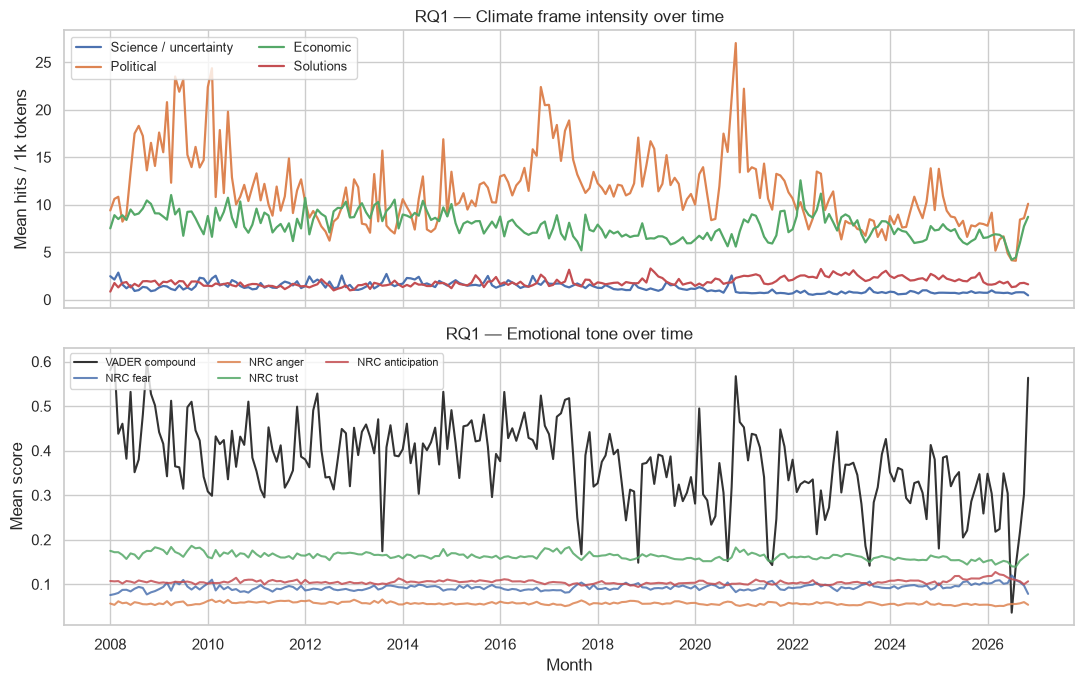

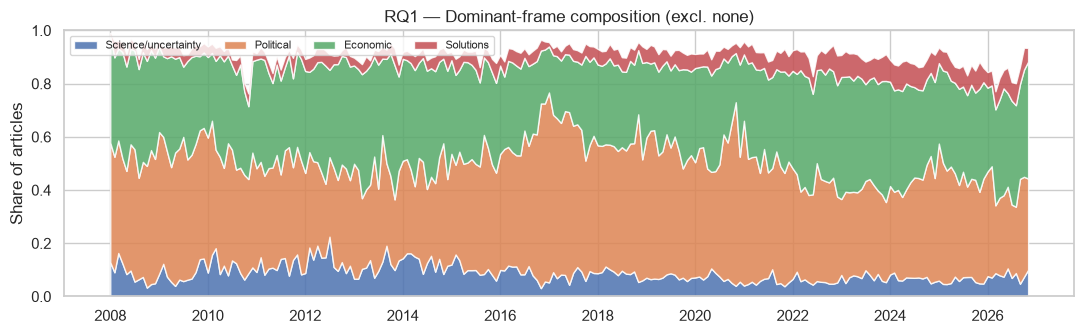

In [55]:
fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)

for col, label in [
    ("frame_science_uncertainty", "Science / uncertainty"),
    ("frame_political", "Political"),
    ("frame_economic", "Economic"),
    ("frame_solutions", "Solutions"),
]:
    axes[0].plot(monthly_plot["month"], monthly_plot[col], label=label, linewidth=1.6)
axes[0].set_ylabel("Mean hits / 1k tokens")
axes[0].set_title("RQ1 — Climate frame intensity over time")
axes[0].legend(loc="upper left", ncol=2, fontsize=9)

axes[1].plot(monthly_plot["month"], monthly_plot["vader_compound"], label="VADER compound", color="#333")
axes[1].plot(monthly_plot["month"], monthly_plot["nrc_fear"], label="NRC fear", alpha=0.85)
axes[1].plot(monthly_plot["month"], monthly_plot["nrc_anger"], label="NRC anger", alpha=0.85)
axes[1].plot(monthly_plot["month"], monthly_plot["nrc_trust"], label="NRC trust", alpha=0.85)
axes[1].plot(monthly_plot["month"], monthly_plot["nrc_anticipation"], label="NRC anticipation", alpha=0.85)
axes[1].set_ylabel("Mean score")
axes[1].set_title("RQ1 — Emotional tone over time")
axes[1].legend(loc="upper left", ncol=3, fontsize=8)
axes[1].set_xlabel("Month")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(11, 3.5))
ax.stackplot(
    monthly_plot["month"],
    monthly_plot["share_science"],
    monthly_plot["share_political"],
    monthly_plot["share_economic"],
    monthly_plot["share_solutions"],
    labels=["Science/uncertainty", "Political", "Economic", "Solutions"],
    alpha=0.85,
)
ax.set_ylim(0, 1)
ax.set_ylabel("Share of articles")
ax.set_title("RQ1 — Dominant-frame composition (excl. none)")
ax.legend(loc="upper left", ncol=4, fontsize=8)
plt.tight_layout()
plt.show()

## Load + recode CCAM (Yale Climate Change in the American Mind)

/var/folders/qz/ndsnrxjx0xgbzf96w5x4fx8h0000gn/T/ipykernel_34774/3721802262.py:1: DtypeWarning: Columns (24: transition_economy, 50: house_head) have mixed types. Specify dtype option on import or set low_memory=False.
  ccam_raw = pd.read_csv(CCAM_PATH)


respondents: 37,495  |  waves: 33


,wave,wave_date,year,n,worry_high,harm_personally_high,harm_US_high,when_harm_soon,discuss_often,hear_media_weekly,support_CO2_reg,support_fund_research,support_transition,priority_high,priority_cleanenergy_high
0,Nov-08,2008-11-01,2008,2164,0.625421,0.315337,0.493971,0.469360,0.401485,NaN,0.797888,0.918581,NaN,0.535589,NaN
1,Jan-10,2010-01-01,2010,1001,0.501345,0.366404,0.506198,0.371319,0.348479,NaN,0.710636,0.848832,NaN,0.383608,0.594672
2,Jun-10,2010-06-01,2010,1024,0.524159,0.309484,0.443241,0.409600,0.355587,NaN,0.766454,0.866732,NaN,0.443693,0.707295
3,May-11,2011-05-01,2011,1010,0.521319,0.295332,0.421816,0.431004,0.303155,NaN,NaN,0.837873,NaN,0.397818,0.659940
4,Nov-11,2011-11-01,2011,1000,0.541990,0.297983,0.437959,0.400201,0.305768,NaN,0.730753,0.772351,NaN,0.371916,0.651430


/var/folders/qz/ndsnrxjx0xgbzf96w5x4fx8h0000gn/T/ipykernel_34774/3721802262.py:17: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  plt.tight_layout()
/Users/lucaslevine/Desktop/project/.venv/lib/python3.14/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


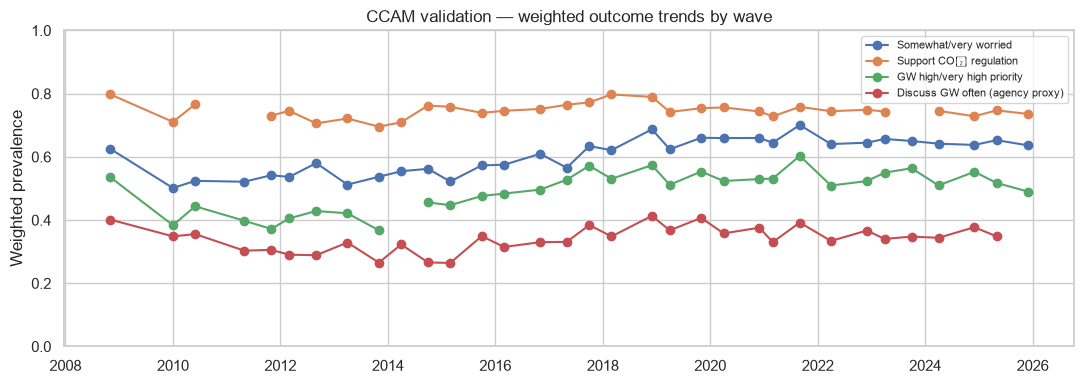

In [56]:
ccam_raw = pd.read_csv(CCAM_PATH)
ccam = apply_recodes(ccam_raw)
wave_out = wave_level_outcomes(ccam)

print(f"respondents: {len(ccam):,}  |  waves: {wave_out['wave'].nunique()}")
display(wave_out.head())

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(wave_out["wave_date"], wave_out["worry_high"], marker="o", label="Somewhat/very worried")
ax.plot(wave_out["wave_date"], wave_out["support_CO2_reg"], marker="o", label="Support CO₂ regulation")
ax.plot(wave_out["wave_date"], wave_out["priority_high"], marker="o", label="GW high/very high priority")
ax.plot(wave_out["wave_date"], wave_out["discuss_often"], marker="o", label="Discuss GW often (agency proxy)")
ax.set_ylim(0, 1)
ax.set_ylabel("Weighted prevalence")
ax.set_title("CCAM validation — weighted outcome trends by wave")
ax.legend(loc="best", fontsize=8)
plt.tight_layout()
plt.show()

## RQ2 — Link media narratives to CCAM waves

For each CCAM wave, aggregate MediaCloud scores in the **90 days before** the wave month. Then correlate and run lagged OLS on levels and first differences.

Associations only — not causal identification.

In [57]:
def media_window_means(media_df: pd.DataFrame, wave_date: pd.Timestamp, days: int = 90) -> dict:
    start = wave_date - pd.Timedelta(days=days)
    end = wave_date
    window = media_df[(media_df["publish_date"] >= start) & (media_df["publish_date"] < end)]
    out = {c: np.nan for c in frame_cols + tone_cols}
    out["n_articles_window"] = 0
    if not window.empty:
        means = window[frame_cols + tone_cols].mean()
        out.update({c: float(means[c]) for c in frame_cols + tone_cols})
        out["n_articles_window"] = int(len(window))
    return out

media_feats = []
for _, row in wave_out.iterrows():
    feats = media_window_means(media, row["wave_date"], days=PRE_WINDOW_DAYS)
    feats["wave"] = row["wave"]
    media_feats.append(feats)

media_by_wave = pd.DataFrame(media_feats)
panel = wave_out.merge(media_by_wave, on="wave", how="left")
panel = panel[panel["n_articles_window"].fillna(0) >= 30].copy()
panel = panel.sort_values("wave_date").reset_index(drop=True)

print(f"waves with ≥30 articles in {PRE_WINDOW_DAYS}-day pre-window: {len(panel)}")
display(panel[["wave", "wave_date", "n_articles_window", "worry_high", "frame_solutions", "vader_compound"]].head(10))

waves with ≥30 articles in 90-day pre-window: 33


,wave,wave_date,n_articles_window,worry_high,frame_solutions,vader_compound
0,Nov-08,2008-11-01,693,0.625421,1.797818,0.502417
1,Jan-10,2010-01-01,2143,0.501345,1.671737,0.392419
2,Jun-10,2010-06-01,1197,0.524159,1.633623,0.427083
3,May-11,2011-05-01,1129,0.521319,1.453848,0.357308
4,Nov-11,2011-11-01,1010,0.541990,1.330458,0.337967
5,Mar-12,2012-03-01,1034,0.536429,1.362918,0.379437
6,Sep-12,2012-09-01,1076,0.580266,1.361944,0.329723
7,Apr-13,2013-04-01,2508,0.512263,1.326599,0.429824
8,Nov-13,2013-11-01,2234,0.536957,1.523504,0.336655
9,Apr-14,2014-04-01,3325,0.554592,1.414790,0.410689


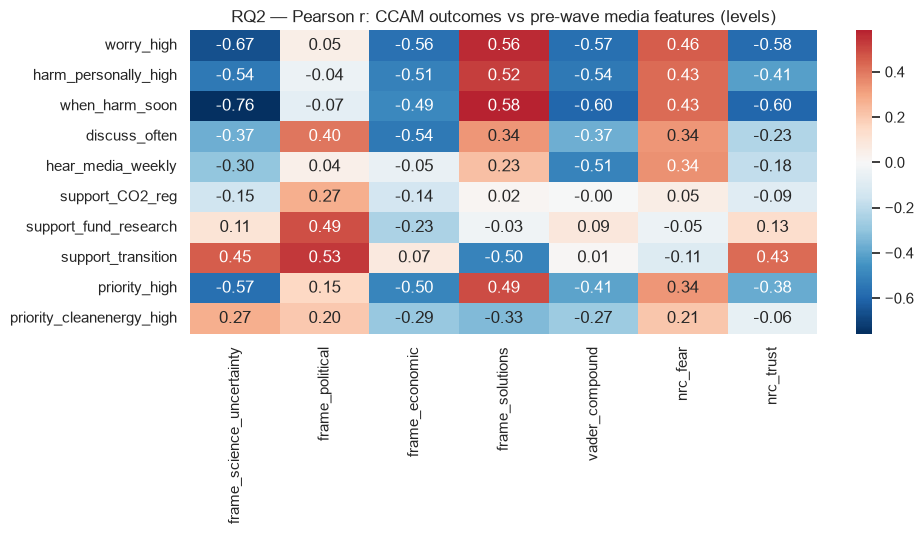

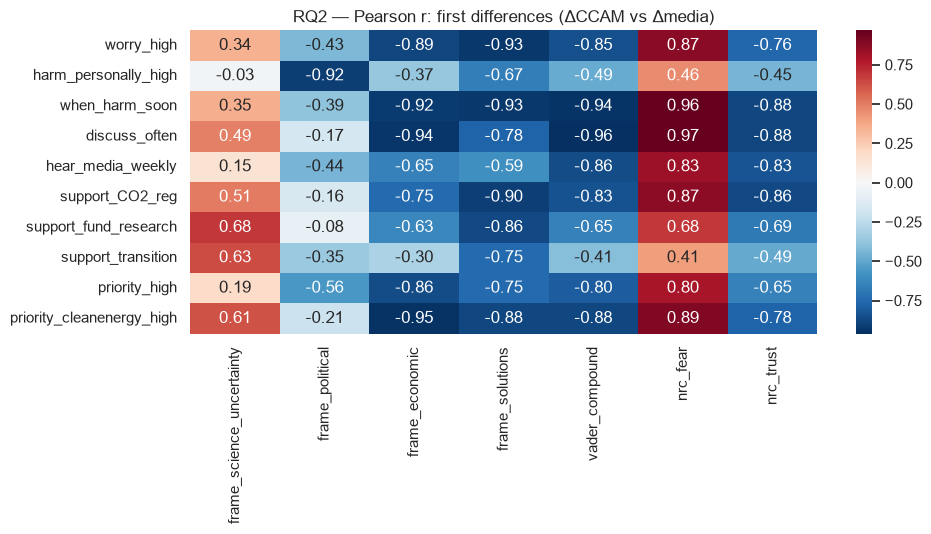

In [58]:
ccam_outcomes = [
    "worry_high",
    "harm_personally_high",
    "when_harm_soon",
    "discuss_often",
    "hear_media_weekly",
    "support_CO2_reg",
    "support_fund_research",
    "support_transition",
    "priority_high",
    "priority_cleanenergy_high",
]
media_predictors = frame_cols + ["vader_compound", "nrc_fear", "nrc_trust"]

# Levels: Pearson correlations
corr_level = panel[ccam_outcomes + media_predictors].corr(method="pearson")
corr_block = corr_level.loc[ccam_outcomes, media_predictors]

fig, ax = plt.subplots(figsize=(10, 5.5))
sns.heatmap(corr_block, annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax)
ax.set_title("RQ2 — Pearson r: CCAM outcomes vs pre-wave media features (levels)")
plt.tight_layout()
plt.show()

# First differences
diff = panel[ccam_outcomes + media_predictors].diff().dropna()
corr_diff = diff.corr(method="pearson").loc[ccam_outcomes, media_predictors]

fig, ax = plt.subplots(figsize=(10, 5.5))
sns.heatmap(corr_diff, annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax)
ax.set_title("RQ2 — Pearson r: first differences (ΔCCAM vs Δmedia)")
plt.tight_layout()
plt.show()

In [59]:
def ols_summary(y: pd.Series, X: pd.DataFrame, label: str) -> pd.DataFrame:
    data = pd.concat([y, X], axis=1).dropna()
    if len(data) < 8:
        print(f"skip {label}: only {len(data)} complete rows")
        return pd.DataFrame()
    yy = data.iloc[:, 0]
    xx = sm.add_constant(data.iloc[:, 1:])
    model = sm.OLS(yy, xx).fit()
    print(f"\n=== {label}  (n={int(model.nobs)}, adj-R²={model.rsquared_adj:.3f}) ===")
    display(model.summary2().tables[1].round(4))
    return model.summary2().tables[1]

# Lagged media → next-wave CCAM (shift media features forward by aligning media at t-1 with outcome at t)
panel_lag = panel.copy()
for c in media_predictors:
    panel_lag[f"lag_{c}"] = panel_lag[c].shift(1)

lag_X_cols = [f"lag_{c}" for c in ["frame_science_uncertainty", "frame_political", "frame_economic", "frame_solutions", "vader_compound"]]

print("Levels OLS (contemporaneous pre-window media)")
ols_summary(
    panel["worry_high"],
    panel[["frame_science_uncertainty", "frame_political", "frame_economic", "frame_solutions", "vader_compound"]],
    "worry_high ~ frames + vader",
)
ols_summary(
    panel["support_CO2_reg"],
    panel[["frame_science_uncertainty", "frame_political", "frame_economic", "frame_solutions", "vader_compound"]],
    "support_CO2_reg ~ frames + vader",
)
ols_summary(
    panel["discuss_often"],
    panel[["frame_solutions", "frame_political", "vader_compound", "nrc_fear"]],
    "discuss_often (agency proxy) ~ solutions/political/tone",
)

print("\nLagged OLS (media at previous wave → CCAM at current wave)")
ols_summary(panel_lag["worry_high"], panel_lag[lag_X_cols], "worry_high ~ lag(media)")
ols_summary(panel_lag["priority_high"], panel_lag[lag_X_cols], "priority_high ~ lag(media)")

print("\nFirst-difference OLS")
d = panel[["worry_high", "support_CO2_reg", "discuss_often"] + media_predictors].diff()
ols_summary(
    d["worry_high"],
    d[["frame_science_uncertainty", "frame_political", "frame_economic", "frame_solutions", "vader_compound"]],
    "Δworry_high ~ Δmedia",
)
ols_summary(
    d["support_CO2_reg"],
    d[["frame_science_uncertainty", "frame_political", "frame_economic", "frame_solutions", "vader_compound"]],
    "Δsupport_CO2_reg ~ Δmedia",
)

Levels OLS (contemporaneous pre-window media)

=== worry_high ~ frames + vader  (n=33, adj-R²=0.670) ===


,Coef.,Std.Err.,t,P>|t|,[0.025,0.975]
const,0.8033,0.0764,10.5172,0.0000,0.6465,0.9600
frame_science_uncertainty,-0.0661,0.0213,-3.1099,0.0044,-0.1097,-0.0225
frame_political,0.0039,0.0023,1.6953,0.1015,-0.0008,0.0086
frame_economic,-0.0132,0.0072,-1.8409,0.0767,-0.0280,0.0015
frame_solutions,0.0136,0.0207,0.6578,0.5162,-0.0288,0.0560
vader_compound,-0.2252,0.1213,-1.8563,0.0744,-0.4741,0.0237



=== support_CO2_reg ~ frames + vader  (n=31, adj-R²=0.008) ===


,Coef.,Std.Err.,t,P>|t|,[0.025,0.975]
const,0.7857,0.0575,13.6650,0.0000,0.6673,0.9041
frame_science_uncertainty,-0.0271,0.0159,-1.7040,0.1008,-0.0600,0.0057
frame_political,0.0028,0.0017,1.6008,0.1220,-0.0008,0.0063
frame_economic,-0.0014,0.0055,-0.2518,0.8032,-0.0126,0.0099
frame_solutions,-0.0190,0.0157,-1.2145,0.2359,-0.0514,0.0133
vader_compound,0.0282,0.0955,0.2951,0.7704,-0.1684,0.2248



=== discuss_often (agency proxy) ~ solutions/political/tone  (n=32, adj-R²=0.414) ===


,Coef.,Std.Err.,t,P>|t|,[0.025,0.975]
const,-0.0474,0.3240,-0.1462,0.8849,-0.7123,0.6175
frame_solutions,0.0277,0.0136,2.0392,0.0513,-0.0002,0.0555
frame_political,0.0069,0.0018,3.7413,0.0009,0.0031,0.0107
vader_compound,-0.1122,0.1560,-0.7193,0.4781,-0.4322,0.2078
nrc_fear,3.1918,2.8708,1.1118,0.2760,-2.6987,9.0822


... (5 outputs left out)

,Coef.,Std.Err.,t,P>|t|,[0.025,0.975]
const,-0.0007,0.0071,-0.0992,0.9218,-0.0152,0.0138
frame_science_uncertainty,-0.0221,0.0239,-0.9254,0.3633,-0.0711,0.0270
frame_political,-0.0013,0.0031,-0.4130,0.6830,-0.0076,0.0050
frame_economic,-0.0014,0.0090,-0.1595,0.8745,-0.0200,0.0171
frame_solutions,-0.0254,0.0238,-1.0681,0.2953,-0.0743,0.0235
vader_compound,-0.1437,0.1567,-0.9176,0.3673,-0.4658,0.1783



=== Δsupport_CO2_reg ~ Δmedia  (n=28, adj-R²=0.397) ===


,Coef.,Std.Err.,t,P>|t|,[0.025,0.975]
const,0.0008,0.0043,0.1935,0.8483,-0.0082,0.0098
frame_science_uncertainty,-0.0456,0.0144,-3.1734,0.0044,-0.0753,-0.0158
frame_political,0.0028,0.0018,1.5612,0.1328,-0.0009,0.0065
frame_economic,0.0111,0.0056,1.9779,0.0606,-0.0005,0.0227
frame_solutions,-0.0448,0.0138,-3.2349,0.0038,-0.0735,-0.0161
vader_compound,-0.1110,0.1020,-1.0880,0.2884,-0.3225,0.1006


,Coef.,Std.Err.,t,P>|t|,[0.025,0.975]
const,0.000839,0.004335,0.193507,0.848337,-0.008151,0.009829
frame_science_uncertainty,-0.045553,0.014355,-3.173360,0.004399,-0.075324,-0.015783
frame_political,0.002788,0.001786,1.561159,0.132757,-0.000916,0.006492
frame_economic,0.011103,0.005614,1.977898,0.060599,-0.000539,0.022745
frame_solutions,-0.044775,0.013841,-3.234880,0.003806,-0.073479,-0.016070
vader_compound,-0.110986,0.102011,-1.087976,0.288382,-0.322545,0.100573


/var/folders/qz/ndsnrxjx0xgbzf96w5x4fx8h0000gn/T/ipykernel_34774/3525281020.py:15: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  plt.tight_layout()
/Users/lucaslevine/Desktop/project/.venv/lib/python3.14/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


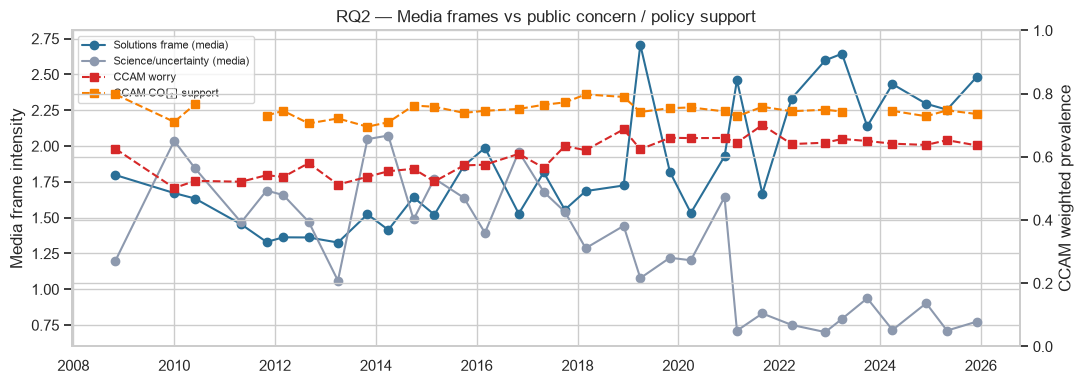

wrote panel: /Users/lucaslevine/Desktop/project/analysis/wave_panel_media_ccam.parquet


In [60]:
# Example joint time-series view: solutions framing vs worry / policy support
fig, ax1 = plt.subplots(figsize=(11, 4))
ax1.plot(panel["wave_date"], panel["frame_solutions"], color="#2a6f97", marker="o", label="Solutions frame (media)")
ax1.plot(panel["wave_date"], panel["frame_science_uncertainty"], color="#8d99ae", marker="o", label="Science/uncertainty (media)")
ax1.set_ylabel("Media frame intensity")
ax2 = ax1.twinx()
ax2.plot(panel["wave_date"], panel["worry_high"], color="#d62828", marker="s", linestyle="--", label="CCAM worry")
ax2.plot(panel["wave_date"], panel["support_CO2_reg"], color="#f77f00", marker="s", linestyle="--", label="CCAM CO₂ support")
ax2.set_ylabel("CCAM weighted prevalence")
ax2.set_ylim(0, 1)
ax1.set_title("RQ2 — Media frames vs public concern / policy support")
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="best", fontsize=8)
plt.tight_layout()
plt.show()

out_path = Path("wave_panel_media_ccam.parquet")
panel.to_parquet(out_path, index=False)
print(f"wrote panel: {out_path}")

## Notes

- Re-run `python analysis/lexicon_frames/score_articles.py` as scraping continues; this notebook picks up new `scores_*.parquet` shards.
- Lexicon frames are transparent but coarse; treat dominant-frame shares as descriptive.
- Wave-level N is small (~dozens of waves with media coverage); prefer correlations / simple OLS over saturated models.
- RQ2 results are **associational** (shared time trends possible).